# Round 1 — blind split measurement

**1,920 blind judgements · 48 candidate pairs · both members · 4 models × 5 draws.**

## ⚠️ No verdict draws have fired

This notebook analyses the **independent variable only**. There is no outcome measure in this
repository. Nothing below may be read as a result about model accuracy, catch rates, or
discrimination — those require the verdict arm, which has not run and is currently blocked.

If a plot here appears to need an outcome variable, it does not belong in this notebook yet.

## Provenance of the factor — three corrections, in order

The thing being measured has been redefined twice and a third redefinition is pending. A reader
should see the sequence and judge it, so it sits here rather than in a footnote.

| # | factor | why it was replaced |
|---|---|---|
| 1 | **assigned taxonomy** (`safe` / `moderate` / `exposed`), by linguistic judgement | Circular: gold would depend on the assigner's own intuition about deontic `will`, with no ground truth outside the assignment. |
| 2 | **raw pooled blind split** — fraction of independent readers who disagree | Measured, not assigned. This is the **pre-registered** factor. |
| 3 | **model-centred split** *(proposed, NOT adopted)* | Raw pooled split is largely between-model offset rather than sentence property — quantified below. |

**Correction 3 has not been applied.** Adopting it would redefine a pre-registered factor after
seeing the IV distribution, and the pinned thresholds (`≤0.20`, `0.21–0.60`, `≥0.61`) are defined on
the raw scale and do not map onto a centred one.

It would also be the *third* correction to one measure. A sequence of individually justified
corrections converging on the version that finally works is hard to distinguish from fitting the
instrument to the data. That judgement is deliberately left to the human and an independent reader.

## The human-baseline gap

**Every reader on both sides of this measurement is a language model.**

Ambiguity is *defined* here by disagreement among four models, and the verdict arm would then score
those same models against that definition. If the four share a reading convention for `will` that
people do not, "ambiguity" is a property of this panel rather than of English — and **nothing
internal to the design can detect that**, because the same population defines the standard and is
tested against it.

The `claim_false` control (below) shows the models understand the *question*. It does not show they
read `will` the way a person does.

A human baseline on even ~12 sentences would anchor this. It has not been collected. Every figure
in this notebook inherits the limitation.

In [1]:
import json, sys, platform
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

SEED = 20260806                      # same seed pinned in the pre-registration
rng = np.random.default_rng(SEED)

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGDIR = REPO / "notebooks" / "figures"; FIGDIR.mkdir(parents=True, exist_ok=True)

print(f"python      {platform.python_version()}")
print(f"numpy       {np.__version__}")
print(f"scipy       {scipy.__version__}")
print(f"matplotlib  {matplotlib.__version__}")
print(f"seed        {SEED}")

python      3.14.2
numpy       2.5.1
scipy       1.18.0
matplotlib  3.11.1
seed        20260806


In [2]:
# Read the scored artifacts. The measurement is NOT recomputed here — these files are the record.
RAW   = json.loads((REPO / "results" / "round1-candidate-splits.json").read_text())
CAND  = json.loads((REPO / "items" / "candidates-round1.json").read_text())

MODELS = ["opus-4.6", "sonnet-4.6", "haiku-4.5", "nova-micro"]
ITEMS  = [c["id"] for c in CAND]
BY     = {c["id"]: c for c in CAND}

# raw rows are (item_id, model, member, verdict) with verdict in {"YES","NO",None}
rows = [tuple(r) for r in RAW]
print(f"{len(rows)} judgements   {len(ITEMS)} items   {len(MODELS)} models")
print(f"members: {sorted(set(r[2] for r in rows))}")
print(f"unparsed/None: {sum(1 for r in rows if r[3] is None)}")
assert len(rows) == len(ITEMS) * len(MODELS) * 2 * 5, "row count does not match the design"

1920 judgements   48 items   4 models
members: ['false', 'true']
unparsed/None: 0


In [3]:
def yes_rate(item=None, model=None, member="true"):
    v = [r[3] for r in rows if r[2] == member and r[3]
         and (item is None or r[0] == item) and (model is None or r[1] == model)]
    return sum(1 for x in v if x == "YES") / len(v) if v else np.nan

def split(item, member="true", model=None):
    # Disagreement among readers: 0 = unanimous, 1 = evenly divided.
    v = [r[3] for r in rows if r[0] == item and r[2] == member and r[3]
         and (model is None or r[1] == model)]
    c = Counter(v); y, n = c.get("YES", 0), c.get("NO", 0)
    return 2 * min(y, n) / (y + n) if (y + n) else np.nan

S_TRUE  = np.array([split(i, "true")  for i in ITEMS])
S_FALSE = np.array([split(i, "false") for i in ITEMS])
print(f"split_true  mean {S_TRUE.mean():.3f}  range [{S_TRUE.min():.2f}, {S_TRUE.max():.2f}]")
print(f"split_false mean {S_FALSE.mean():.3f}  range [{S_FALSE.min():.2f}, {S_FALSE.max():.2f}]")

split_true  mean 0.444  range [0.00, 1.00]
split_false mean 0.071  range [0.00, 0.40]


## Validity cuts — shown, not silently dropped

An item is admissible only if its **`claim_false` member is unambiguous** (`split_false ≤ 0.20`).
`claim_false` is a plain present-tense assertion; if readers cannot agree on what *it* asserts, the
item has two moving parts and cannot isolate anything.

In [4]:
VALID_MAX = 0.20
cut  = [i for i, s in zip(ITEMS, S_FALSE) if s > VALID_MAX]
keep = [i for i, s in zip(ITEMS, S_FALSE) if s <= VALID_MAX]
print(f"admissible {len(keep)}/{len(ITEMS)}   cut {len(cut)}\n")
for i in cut:
    print(f"  CUT  {i}  split_false={split(i,'false'):.2f} > {VALID_MAX}   "
          f"(split_true={split(i,'true'):.2f})   \"{BY[i]['claim_false']}\"")

admissible 43/48   cut 5

  CUT  m07  split_false=0.30 > 0.2   (split_true=0.00)   "The legacy password column has been dropped."
  CUT  m24  split_false=0.30 > 0.2   (split_true=0.90)   "Readiness reflects the database connection."
  CUT  m33  split_false=0.30 > 0.2   (split_true=0.10)   "Client errors are excluded from retries."
  CUT  m46  split_false=0.30 > 0.2   (split_true=0.20)   "A failed deploy has been made to revert automatically."
  CUT  m48  split_false=0.40 > 0.2   (split_true=0.50)   "Liveness has been separated from readiness."


## Figure A — the panel-offset result

The strongest finding available. Four models are shown the *same* sentence with no context and asked
whether it asserts something about how the system behaves **now**.

The `claim_false` control is in the same axes deliberately: it is what rules out *"they didn't
understand the question."*

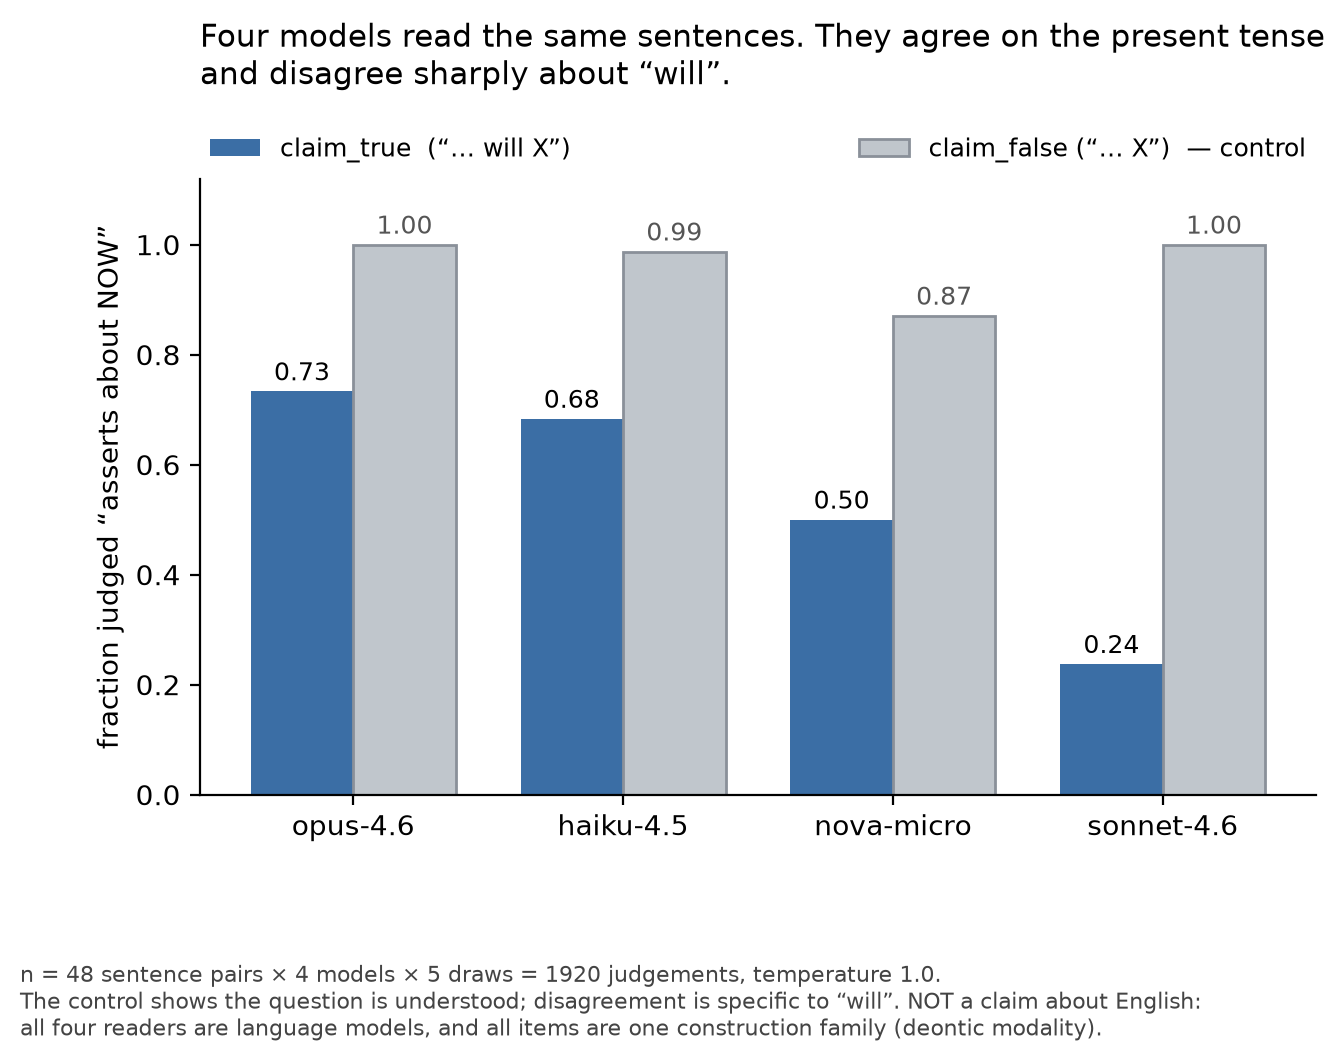

In [5]:
ytrue  = [yes_rate(model=m, member="true")  for m in MODELS]
yfalse = [yes_rate(model=m, member="false") for m in MODELS]
order  = np.argsort(ytrue)[::-1]
lab    = [MODELS[i] for i in order]
vt     = [ytrue[i] for i in order]; vf = [yfalse[i] for i in order]

fig, ax = plt.subplots(figsize=(7.2, 4.0), dpi=200)
x = np.arange(len(lab)); w = 0.38
ax.bar(x - w/2, vt, w, label="claim_true  (“… will X”)", color="#3b6ea5")
ax.bar(x + w/2, vf, w, label="claim_false (“… X”)  — control", color="#c0c6cc", edgecolor="#8a9099")
for xi, v in zip(x - w/2, vt): ax.text(xi, v + .02, f"{v:.2f}", ha="center", fontsize=9)
for xi, v in zip(x + w/2, vf): ax.text(xi, v + .02, f"{v:.2f}", ha="center", fontsize=9, color="#555")
ax.set_xticks(x); ax.set_xticklabels(lab); ax.set_ylim(0, 1.12)
ax.set_ylabel("fraction judged “asserts about NOW”")
# legend ABOVE the axes: at ylim 1.12 the control bars reach the top-right corner and an in-axes
# legend collides with sonnet's 1.00 label.
ax.legend(frameon=False, fontsize=9, ncol=2, loc="lower left",
          bbox_to_anchor=(0, 1.01, 1, .12), mode="expand", borderaxespad=0)
ax.set_title("Four models read the same sentences. They agree on the present tense\n"
             "and disagree sharply about “will”.", fontsize=11, loc="left", pad=34)
ax.spines[["top","right"]].set_visible(False)
fig.text(0.0, -0.10,
  f"n = {len(ITEMS)} sentence pairs × {len(MODELS)} models × 5 draws = {len(rows)} judgements, "
  f"temperature 1.0.\nThe control shows the question is understood; disagreement is specific to "
  f"“will”. NOT a claim about English:\nall four readers are language models, and all items are one "
  f"construction family (deontic modality).", fontsize=8, va="top", color="#444")
FIG_A = fig
plt.show()

## Figure B — raw pooled split vs model-centred split

Why the pre-registered factor is suspect. **Raw pooled split** mixes two things:

- how much a single reader wavers on a sentence (**within**-model), and
- how far apart the readers' baselines sit (**between**-model).

Only the first is a property of the sentence.

mean within-model split 0.131   mean pooled split 0.444   -> between-model share 70%


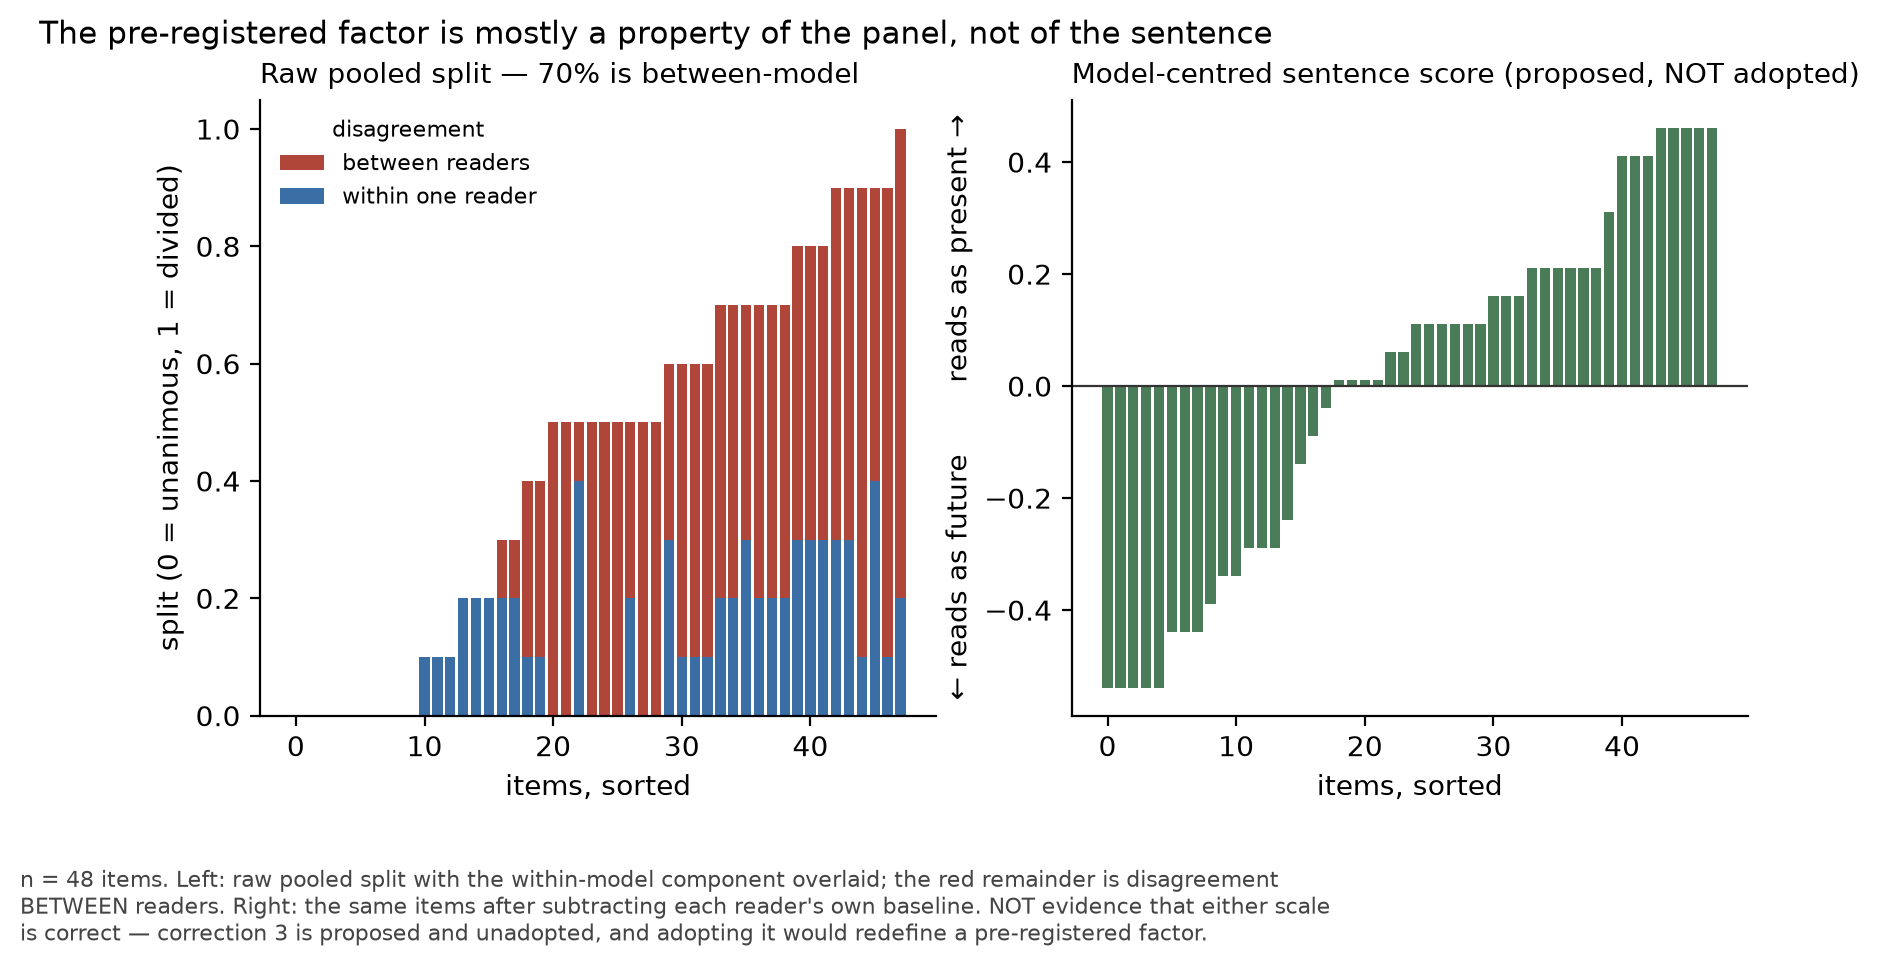

In [6]:
# per-item, per-model YES-rate on claim_true
Y = np.array([[yes_rate(item=i, model=m, member="true") for m in MODELS] for i in ITEMS])
model_offset = Y.mean(axis=0)                       # each reader's own baseline
Y_cent       = Y - model_offset                     # remove it
item_score   = Y_cent.mean(axis=1)                  # sentence score, offset-free

within = np.array([np.mean([split(i, "true", m) for m in MODELS]) for i in ITEMS])
between_share = 1 - within.mean() / S_TRUE.mean()

fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.0), dpi=200)
o = np.argsort(S_TRUE)
# Both components carry labels and share one legend. A floating annotation next to a legend
# collided with it; encoding the same information IN the legend removes the failure mode.
axes[0].bar(range(len(ITEMS)), S_TRUE[o], color="#b0453a", label="between readers")
axes[0].bar(range(len(ITEMS)), within[o], color="#3b6ea5", label="within one reader")
axes[0].set_title(f"Raw pooled split — {between_share:.0%} is between-model", fontsize=10, loc="left")
axes[0].set_ylabel("split (0 = unanimous, 1 = divided)"); axes[0].set_xlabel("items, sorted")
axes[0].legend(frameon=False, fontsize=8, loc="upper left", title="disagreement",
               title_fontsize=8)

o2 = np.argsort(item_score)
axes[1].bar(range(len(ITEMS)), item_score[o2], color="#4a7c59")
axes[1].axhline(0, color="#333", lw=.8)
axes[1].set_title("Model-centred sentence score (proposed, NOT adopted)", fontsize=10, loc="left")
axes[1].set_ylabel("← reads as future        reads as present →"); axes[1].set_xlabel("items, sorted")
for a in axes: a.spines[["top","right"]].set_visible(False)
fig.suptitle("The pre-registered factor is mostly a property of the panel, not of the sentence",
             fontsize=11, x=0.01, ha="left")
fig.text(0.0, -0.08,
  f"n = {len(ITEMS)} items. Left: raw pooled split with the within-model component overlaid; the red "
  f"remainder is disagreement\nBETWEEN readers. Right: the same items after subtracting each "
  f"reader's own baseline. NOT evidence that either scale\nis correct — correction 3 is proposed and "
  f"unadopted, and adopting it would redefine a pre-registered factor.", fontsize=8, va="top", color="#444")
FIG_B = fig
print(f"mean within-model split {within.mean():.3f}   mean pooled split {S_TRUE.mean():.3f}"
      f"   -> between-model share {between_share:.0%}")
plt.show()

## Figure C — after centring, the readers agree on *which* sentences are slippery

The distinction the whole finding rests on, and the one easiest to lose:

**models disagree about their baseline for `will`, and agree about which sentences are slippery.**

Raw per-item correlations look near-zero only because the offset dominates them.

item share of centred variance: 60.7%
  opus-4.6 × sonnet-4.6            rho=+0.404 p=0.0044
  opus-4.6 × haiku-4.5             rho=+0.600 p=0.0000
  opus-4.6 × nova-micro            rho=+0.663 p=0.0000
  sonnet-4.6 × haiku-4.5           rho=+0.563 p=0.0000
  sonnet-4.6 × nova-micro          rho=+0.285 p=0.0492
  haiku-4.5 × nova-micro           rho=+0.518 p=0.0002


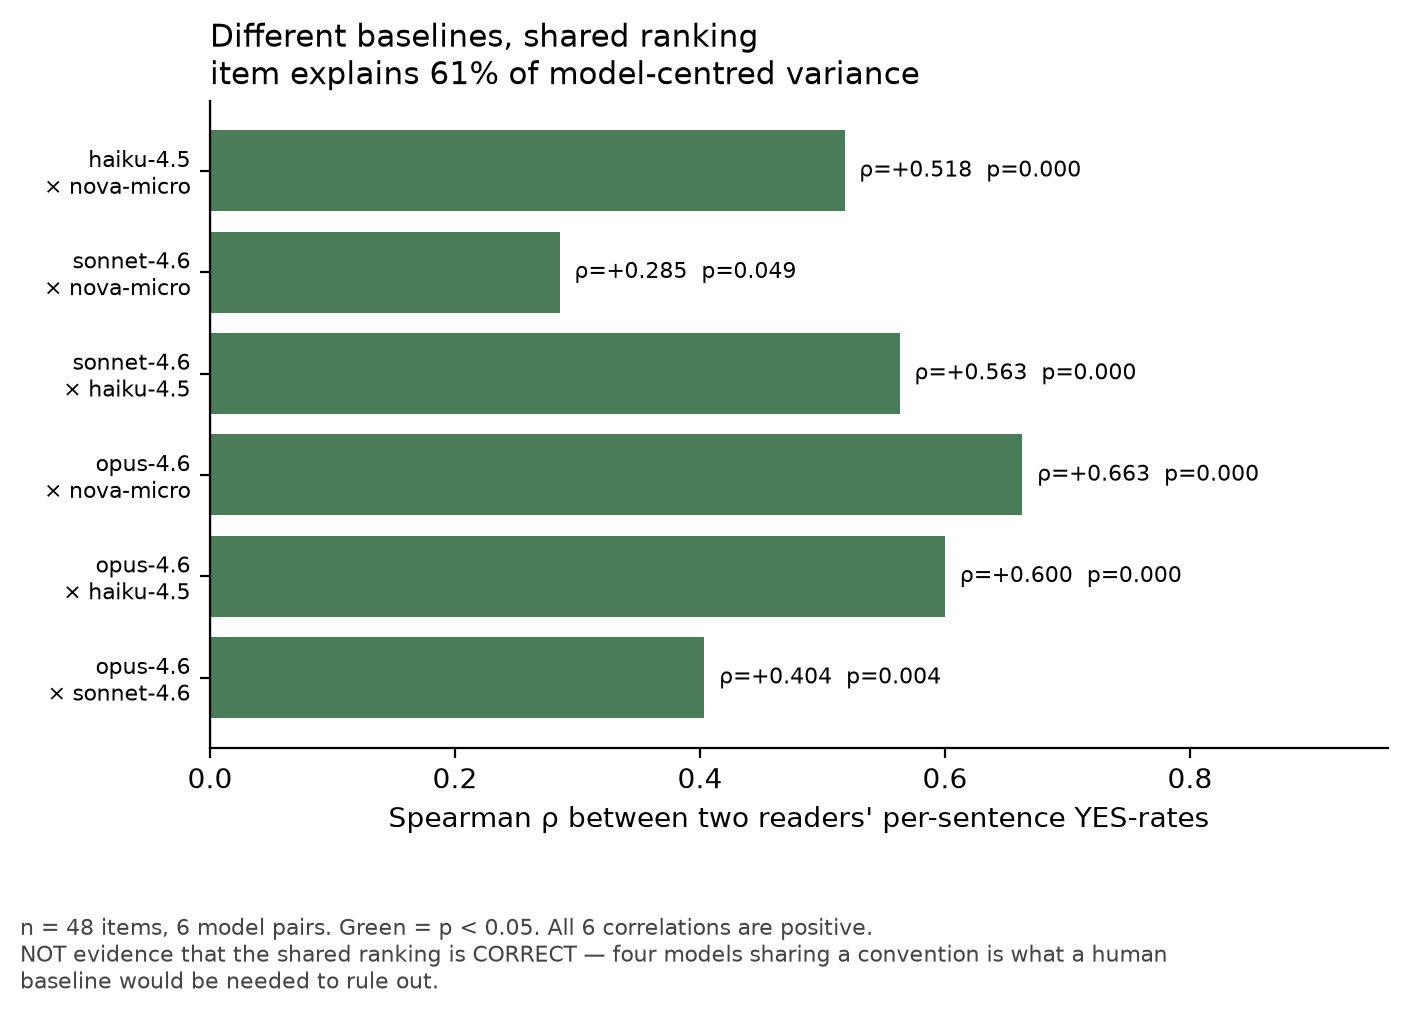

In [7]:
pairs, rhos, ps = [], [], []
for a in range(len(MODELS)):
    for b in range(a + 1, len(MODELS)):
        r, p = stats.spearmanr(Y[:, a], Y[:, b])
        pairs.append(f"{MODELS[a]}\n× {MODELS[b]}"); rhos.append(r); ps.append(p)

# variance attributable to item, after removing model offsets
grand  = item_score.mean()
ss_item = ((item_score - grand) ** 2).sum() * len(MODELS)
resid   = Y_cent - item_score[:, None]
ss_res  = (resid ** 2).sum()
item_share = ss_item / (ss_item + ss_res)

fig, ax = plt.subplots(figsize=(7.6, 4.2), dpi=200)
col = ["#4a7c59" if p < .05 else "#b8b8b8" for p in ps]
ax.barh(range(len(pairs)), rhos, color=col)
ax.set_yticks(range(len(pairs))); ax.set_yticklabels(pairs, fontsize=8)
ax.axvline(0, color="#333", lw=.8)
for i, (r, p) in enumerate(zip(rhos, ps)):
    ax.text(r + .012, i, f"ρ={r:+.3f}  p={p:.3f}", va="center", fontsize=8)
ax.set_xlim(0, max(rhos) * 1.45)
ax.set_xlabel("Spearman ρ between two readers' per-sentence YES-rates")
ax.set_title(f"Different baselines, shared ranking\n"
             f"item explains {item_share:.0%} of model-centred variance", fontsize=11, loc="left")
ax.spines[["top","right"]].set_visible(False)
fig.text(0.0, -0.09,
  f"n = {len(ITEMS)} items, {len(pairs)} model pairs. Green = p < 0.05. All {len(pairs)} correlations "
  f"are positive.\nNOT evidence that the shared ranking is CORRECT — four models sharing a convention "
  f"is what a human\nbaseline would be needed to rule out.", fontsize=8, va="top", color="#444")
FIG_C = fig
print(f"item share of centred variance: {item_share:.1%}")
for pr, r, p in zip(pairs, rhos, ps): print(f"  {pr.replace(chr(10),' '):32s} rho={r:+.3f} p={p:.4f}")
plt.show()

## Figure D — the control, and the pre-registered STOP condition

If `claim_false` members split high on the same items as their `claim_true` twins, the split score is
tracking future-tense marking or item weirdness rather than ambiguity — and the factor is not what
the design assumes. The pre-registration makes a positive correlation here a **STOP condition**.

STOP condition rho=-0.091 p=0.539 -> PASS
items high on BOTH members: none


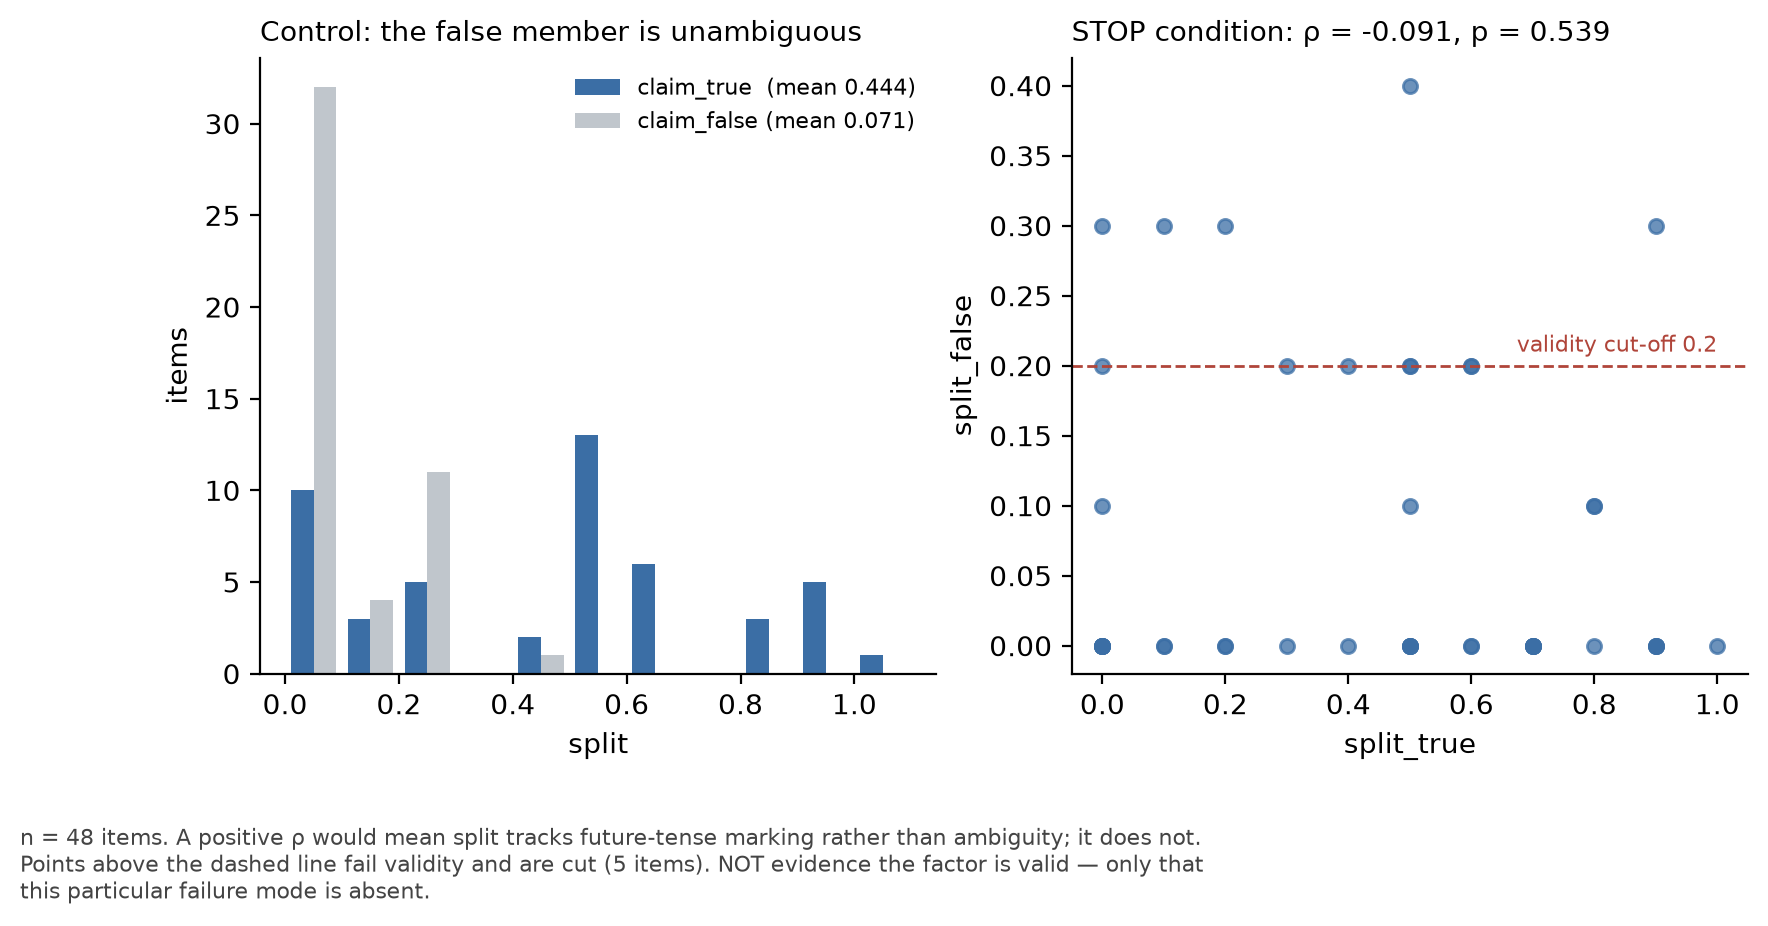

In [8]:
rho_ctrl, p_ctrl = stats.spearmanr(S_TRUE, S_FALSE)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.0), dpi=200)
axes[0].hist([S_TRUE, S_FALSE], bins=np.arange(0, 1.101, .1),
             label=[f"claim_true  (mean {S_TRUE.mean():.3f})",
                    f"claim_false (mean {S_FALSE.mean():.3f})"],
             color=["#3b6ea5", "#c0c6cc"])
axes[0].set_xlabel("split"); axes[0].set_ylabel("items"); axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title("Control: the false member is unambiguous", fontsize=10, loc="left")

axes[1].scatter(S_TRUE, S_FALSE, s=26, color="#3b6ea5", alpha=.75)
axes[1].axhline(VALID_MAX, color="#b0453a", ls="--", lw=1)
axes[1].text(1.0, VALID_MAX + .01, f"validity cut-off {VALID_MAX}", ha="right",
             fontsize=8, color="#b0453a")
axes[1].set_xlabel("split_true"); axes[1].set_ylabel("split_false")
axes[1].set_title(f"STOP condition: ρ = {rho_ctrl:+.3f}, p = {p_ctrl:.3f}", fontsize=10, loc="left")
for a in axes: a.spines[["top","right"]].set_visible(False)
fig.text(0.0, -0.08,
  f"n = {len(ITEMS)} items. A positive ρ would mean split tracks future-tense marking rather than "
  f"ambiguity; it does not.\nPoints above the dashed line fail validity and are cut ({len(cut)} items). "
  f"NOT evidence the factor is valid — only that\nthis particular failure mode is absent.",
  fontsize=8, va="top", color="#444")
FIG_D = fig
print(f"STOP condition rho={rho_ctrl:+.3f} p={p_ctrl:.3f} -> "
      f"{'STOP' if (rho_ctrl > 0.5 and p_ctrl < .05) else 'PASS'}")
print(f"items high on BOTH members: "
      f"{[i for i in ITEMS if split(i,'true')>=.5 and split(i,'false')>=.5] or 'none'}")
plt.show()

## Figure E — construction check

The 48 contain two visibly distinct constructions. If they split differently, the continuous factor
has a **categorical variable inside it**, and an effect attributed to *ambiguity* could be an effect
of *construction*.

The answer is not assumed here — the grouping is derived from each item's declared `token_delta`.

bare will       n=33 mean 0.500 median 0.50
perfect→future  n=15 mean 0.320 median 0.30
Mann-Whitney U=332 p=0.02882


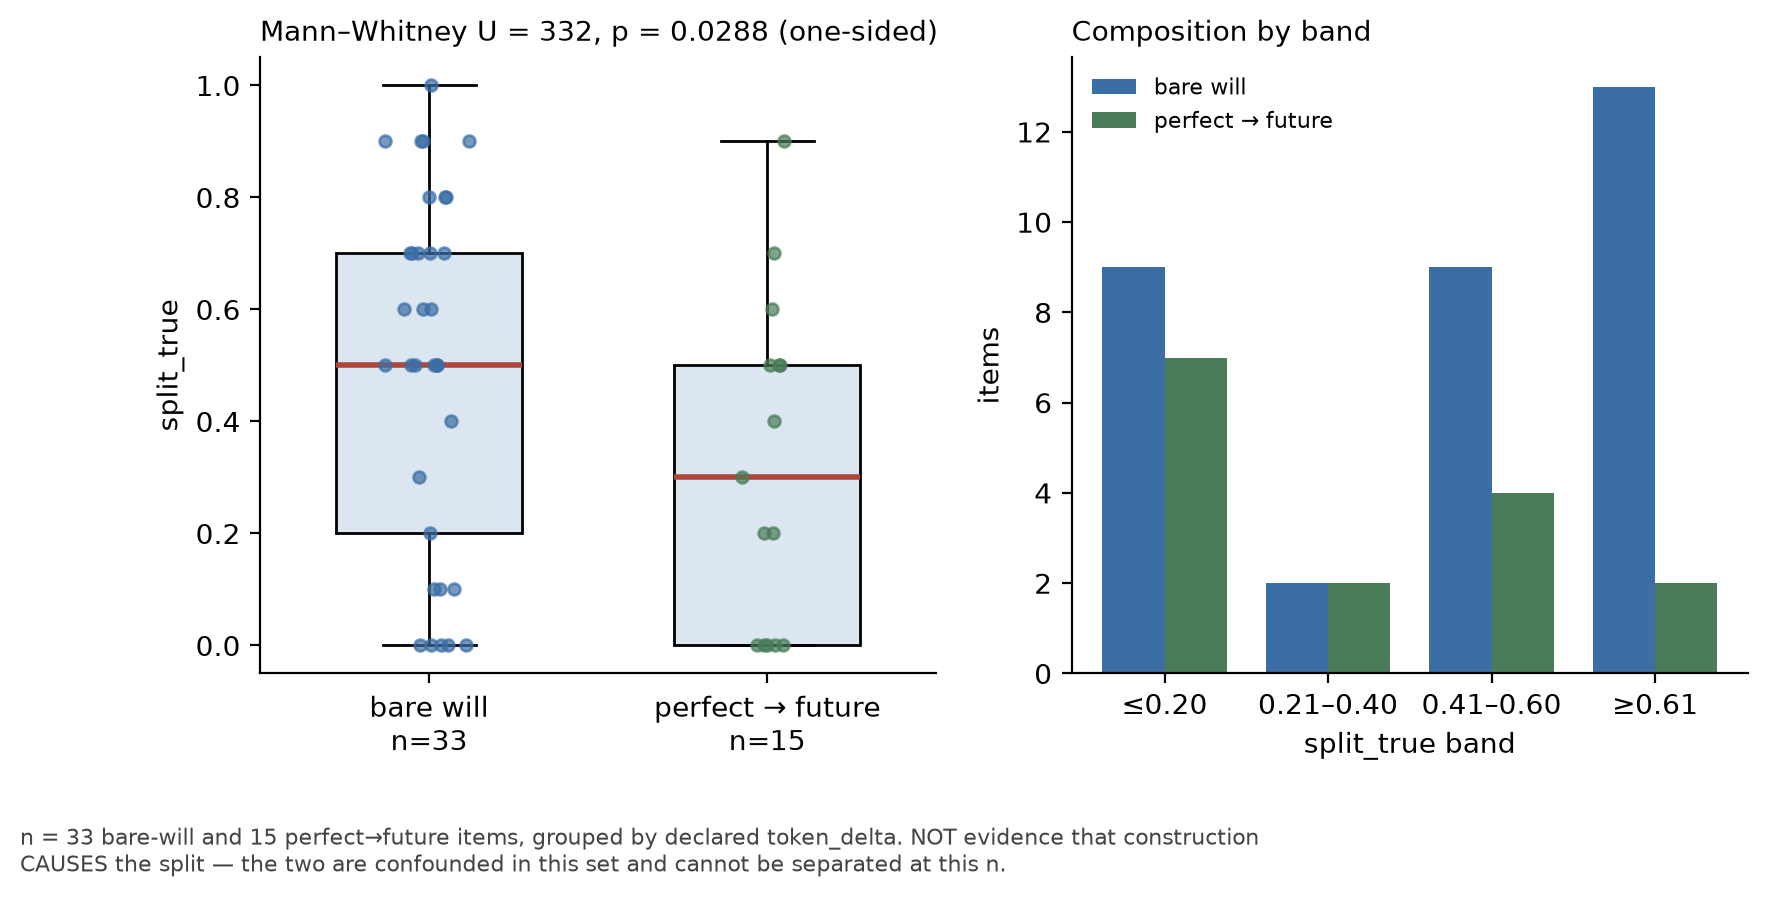

In [9]:
def construction(c):
    f = c["token_delta"]["from"].lower()
    return "perfect → future" if f.startswith(("has ", "have ")) else "bare will"

grp = {}
for c in CAND: grp.setdefault(construction(c), []).append(c["id"])
A = np.array([split(i, "true") for i in grp["bare will"]])
B = np.array([split(i, "true") for i in grp["perfect → future"]])
U, p_u = stats.mannwhitneyu(A, B, alternative="greater")

fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.0), dpi=200)
axes[0].boxplot([A, B], tick_labels=[f"bare will\nn={len(A)}", f"perfect → future\nn={len(B)}"],
                widths=.55, patch_artist=True,
                boxprops=dict(facecolor="#dce6f0"), medianprops=dict(color="#b0453a", lw=2))
axes[0].scatter(rng.normal(1, .05, len(A)), A, s=18, color="#3b6ea5", alpha=.7, zorder=3)
axes[0].scatter(rng.normal(2, .05, len(B)), B, s=18, color="#4a7c59", alpha=.7, zorder=3)
axes[0].set_ylabel("split_true")
axes[0].set_title(f"Mann–Whitney U = {U:.0f}, p = {p_u:.4f} (one-sided)", fontsize=10, loc="left")

BANDS = [(0, .20, "≤0.20"), (.21, .40, "0.21–0.40"), (.41, .60, "0.41–0.60"), (.61, 1.01, "≥0.61")]
bw = .38
for k, (gname, colr) in enumerate((("bare will", "#3b6ea5"), ("perfect → future", "#4a7c59"))):
    counts = [sum(1 for i in grp[gname] if lo <= split(i, "true") <= hi) for lo, hi, _ in BANDS]
    axes[1].bar(np.arange(len(BANDS)) + (k - .5) * bw, counts, bw, label=gname, color=colr)
axes[1].set_xticks(range(len(BANDS))); axes[1].set_xticklabels([b[2] for b in BANDS])
axes[1].set_xlabel("split_true band"); axes[1].set_ylabel("items")
axes[1].legend(frameon=False, fontsize=8)
axes[1].set_title("Composition by band", fontsize=10, loc="left")
for a in axes: a.spines[["top","right"]].set_visible(False)
fig.text(0.0, -0.08,
  f"n = {len(A)} bare-will and {len(B)} perfect→future items, grouped by declared token_delta. "
  f"NOT evidence that construction\nCAUSES the split — the two are confounded in this set and cannot "
  f"be separated at this n.", fontsize=8, va="top", color="#444")
FIG_E = fig
print(f"bare will       n={len(A):2d} mean {A.mean():.3f} median {np.median(A):.2f}")
print(f"perfect→future  n={len(B):2d} mean {B.mean():.3f} median {np.median(B):.2f}")
print(f"Mann-Whitney U={U:.0f} p={p_u:.5f}")
plt.show()

## Figure F — band fill as measured

Target was 6 items per band. Shown as measured; underfilled bands are **not** back-filled, because
filling from an adjacent band would flatten the factor, and no candidate may be authored now that
its own split is known.

  ≤0.20      n=13 OK           ['m03', 'm06', 'm13', 'm17', 'm20', 'm26', 'm27', 'm29', 'm37', 'm38', 'm42', 'm43', 'm45']
  0.21–0.40  n= 4 UNDERFILLED  ['m11', 'm22', 'm30', 'm31']
  0.41–0.60  n=12 OK           ['m08', 'm10', 'm12', 'm16', 'm18', 'm23', 'm25', 'm28', 'm34', 'm35', 'm39', 'm40']
  ≥0.61      n=14 OK           ['m01', 'm02', 'm04', 'm05', 'm09', 'm14', 'm15', 'm19', 'm21', 'm32', 'm36', 'm41', 'm44', 'm47']


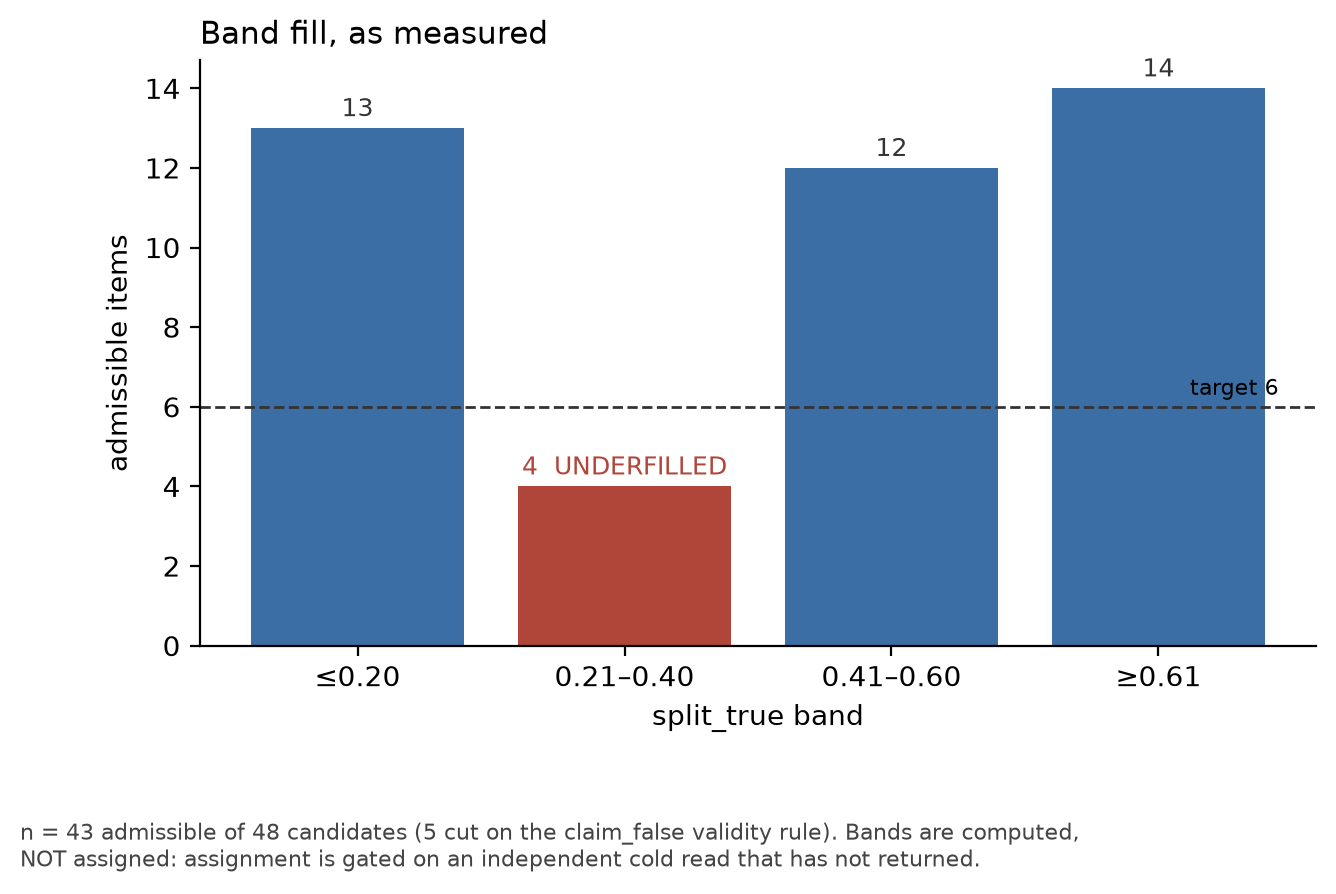

In [10]:
fill = []
for lo, hi, lab in BANDS:
    ids = [i for i in keep if lo <= split(i, "true") <= hi]
    fill.append((lab, ids))
TARGET = 6
fig, ax = plt.subplots(figsize=(7.2, 3.8), dpi=200)
n = [len(v) for _, v in fill]
col = ["#b0453a" if c < TARGET else "#3b6ea5" for c in n]
ax.bar([f[0] for f in fill], n, color=col)
ax.axhline(TARGET, color="#333", ls="--", lw=1)
ax.text(3.45, TARGET + .3, f"target {TARGET}", ha="right", fontsize=8)
for i, c in enumerate(n):
    ax.text(i, c + .3, f"{c}" + ("  UNDERFILLED" if c < TARGET else ""), ha="center", fontsize=9,
            color="#b0453a" if c < TARGET else "#333")
ax.set_ylabel("admissible items"); ax.set_xlabel("split_true band")
ax.set_title("Band fill, as measured", fontsize=11, loc="left")
ax.spines[["top","right"]].set_visible(False)
fig.text(0.0, -0.12,
  f"n = {len(keep)} admissible of {len(ITEMS)} candidates ({len(cut)} cut on the claim_false validity "
  f"rule). Bands are computed,\nNOT assigned: assignment is gated on an independent cold read that has "
  f"not returned.", fontsize=8, va="top", color="#444")
FIG_F = fig
for lab, ids in fill:
    print(f"  {lab:10s} n={len(ids):2d} {'UNDERFILLED' if len(ids)<TARGET else 'OK':12s} {ids}")
plt.show()

## Export — article figures

Written from the *same* figure objects the analysis produced, so a figure in the article cannot
drift from the cell that generated it. Re-running this notebook top-to-bottom regenerates both.

In [11]:
EXPORTS = {"figA-panel-offset": FIG_A, "figB-raw-vs-centred": FIG_B,
           "figC-agreement-after-centring": FIG_C, "figD-control-and-stop": FIG_D,
           "figE-construction": FIG_E, "figF-band-fill": FIG_F}
for name, f in EXPORTS.items():
    for ext in ("png", "svg"):
        p = FIGDIR / f"{name}.{ext}"
        f.savefig(p, dpi=200, bbox_inches="tight", facecolor="white")
    print(f"  {name}.png / .svg")
print(f"\n-> {FIGDIR}")

  figA-panel-offset.png / .svg


  figB-raw-vs-centred.png / .svg
  figC-agreement-after-centring.png / .svg


  figD-control-and-stop.png / .svg


  figE-construction.png / .svg
  figF-band-fill.png / .svg

-> /Users/andrewwint/Documents/PROJECTS/PERSONAL/single-token-eval/notebooks/figures


## What this notebook does not show

- **No outcome measure.** No verdict draw has fired. Nothing here speaks to whether models *catch*
  anything.
- **No human baseline.** Every reader is a model, on both sides of the measurement.
- **One construction family.** All 48 items are deontic-modality candidates. The presupposition
  mechanism (`will no longer X`) — which includes the study's own originating example — sits outside
  this population and is carried elsewhere as recorded instances, not as evidence.
- **Bands are computed, not assigned.** Assignment is gated on an independent cold read.